# 01 — Exploratory Data Analysis

**Predictive E-Commerce Business Intelligence Platform** · Olist marketplace dataset

This notebook answers *"what is in this data, and what does it say about the business?"*
Its output is a set of **requirements for the ETL pipeline** (Module 3) and a set of
**baseline numbers** that the MySQL warehouse and the Power BI dashboard must
reproduce exactly.

Two rules this notebook follows:

1. **Every KPI uses the locked definitions** declared in the config cell below. If the
   notebook, the SQL layer and the dashboard each invent their own revenue formula, the
   three will disagree on stage — this is where that is prevented.
2. **Outliers are investigated, never silently dropped.** A R$6,735 product and a
   209-day delivery are real events in a marketplace, not data errors.

Sections
1. Structural EDA — shape, dtypes, nulls, duplicates, cardinality
2. Data quality — the nine traps in this dataset
3. Headline business KPIs
4. Trends over time
5. Products & categories
6. Customer experience — reviews & delivery
7. Payments
8. Geography
9. Repeat purchase behaviour
10. Outliers
11. Findings → ETL requirements

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd()
while not (ROOT / "data" / "raw").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw"
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("project root :", ROOT.name)

REVENUE_STATUS = "delivered"
PERSON_KEY     = "customer_unique_id"

SURFACE   = "#fcfcfb"
INK       = "#0b0b0b"
INK_2     = "#52514e"
MUTED     = "#898781"
GRID      = "#e1e0d9"
AXIS      = "#c3c2b7"
SERIES    = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
             "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
GOOD, WARN, SERIOUS, CRITICAL = "#0ca30c", "#fab219", "#ec835a", "#d03b3b"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "600",
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "lines.linewidth": 2, "lines.markersize": 8, "legend.frameon": False,
})

def finish(ax, title, sub=None, save=None):
    ax.set_title(title, loc="left", pad=18 if sub else 10)
    if sub:
        ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=9, color=MUTED, va="bottom")
    if save:
        plt.savefig(FIG / f"{save}.png")
    plt.show()

def brl(x, _=None):
    if abs(x) >= 1e6:  return f"R${x/1e6:.1f}M"
    if abs(x) >= 1e3:  return f"R${x/1e3:.0f}K"
    return f"R${x:.0f}"

print("visual system loaded")

project root : dataproject
visual system loaded


## Load the raw data

Raw files are opened read-only and never written back — `data/raw/` is immutable.

In [2]:
TABLES = ["customers", "orders", "order_items", "payments",
          "reviews", "products", "sellers", "geolocation", "category_translation"]

df = {t: pd.read_csv(RAW / f"{t}.csv") for t in TABLES}

customers, orders, order_items = df["customers"], df["orders"], df["order_items"]
payments, reviews, products    = df["payments"], df["reviews"], df["products"]
sellers, geolocation, cat_tr   = df["sellers"], df["geolocation"], df["category_translation"]

DATE_COLS = ["order_purchase_timestamp", "order_approved_at",
             "order_delivered_carrier_date", "order_delivered_customer_date",
             "order_estimated_delivery_date"]
for c in DATE_COLS:
    orders[c] = pd.to_datetime(orders[c], errors="coerce")

print(f"{len(TABLES)} tables loaded")

9 tables loaded


## 1 · Structural EDA

Shape, dtypes, missing values, duplicates and cardinality — for every table at once
rather than nine repetitions of `.info()`.

In [3]:
summary = pd.DataFrame([{
    "table":    t,
    "rows":     len(d),
    "cols":     d.shape[1],
    "full_dupes": int(d.duplicated().sum()),
    "cols_with_nulls": int((d.isna().sum() > 0).sum()),
    "total_nulls": int(d.isna().sum().sum()),
    "memory_mb": round(d.memory_usage(deep=True).sum() / 1e6, 1),
} for t, d in df.items()]).set_index("table")

summary.style.format(thousands=",").set_caption("Table inventory")

,rows,cols,full_dupes,cols_with_nulls,total_nulls,memory_mb
table,,,,,,
customers,"99,441",5,0,0,0,27.900000
orders,"99,441",8,0,3,"4,908",25.900000
order_items,"112,650",7,0,0,0,37.700000
payments,"103,886",5,0,0,0,17.000000
reviews,"99,224",7,0,2,"145,903",41.000000
products,"32,951",9,0,8,"2,448",6.600000
sellers,"3,095",4,0,0,0,0.600000
geolocation,"1,000,163",5,"261,831",0,0,136.600000
category_translation,71,2,0,0,0,0.000000


In [4]:
def profile(name):
    d = df[name]
    out = pd.DataFrame({
        "dtype":     d.dtypes.astype(str),
        "nulls":     d.isna().sum(),
        "null_pct":  (100 * d.isna().mean()).round(2),
        "unique":    d.nunique(),
        "example":   [d[c].dropna().iloc[0] if d[c].notna().any() else None for c in d.columns],
    })
    out.index.name = f"{name}  ({len(d):,} rows)"
    return out

profile("orders")

,dtype,nulls,null_pct,unique,example
"orders (99,441 rows)",,,,,
order_id,object,0,0.00,99441,e481f51cbdc54678b7cc49136f2d6af7
customer_id,object,0,0.00,99441,9ef432eb6251297304e76186b10a928d
order_status,object,0,0.00,8,delivered
order_purchase_timestamp,datetime64[ns],0,0.00,98875,2017-10-02 10:56:33
order_approved_at,datetime64[ns],160,0.16,90733,2017-10-02 11:07:15
order_delivered_carrier_date,datetime64[ns],1783,1.79,81018,2017-10-04 19:55:00
order_delivered_customer_date,datetime64[ns],2965,2.98,95664,2017-10-10 21:25:13
order_estimated_delivery_date,datetime64[ns],0,0.00,459,2017-10-18 00:00:00


In [5]:
nulls = []
for t, d in df.items():
    s = d.isna().sum()
    for col, n in s[s > 0].items():
        nulls.append({"table": t, "column": col, "nulls": int(n),
                      "pct": round(100 * n / len(d), 2)})

nulls_df = pd.DataFrame(nulls).sort_values("pct", ascending=False)
print("Columns containing missing values:\n")
print(nulls_df.to_string(index=False))

Columns containing missing values:

   table                        column  nulls   pct
 reviews          review_comment_title  87656 88.34
 reviews        review_comment_message  58247 58.70
  orders order_delivered_customer_date   2965  2.98
products         product_category_name    610  1.85
products           product_name_lenght    610  1.85
products    product_description_lenght    610  1.85
products            product_photos_qty    610  1.85
  orders  order_delivered_carrier_date   1783  1.79
  orders             order_approved_at    160  0.16
products              product_weight_g      2  0.01
products             product_length_cm      2  0.01
products             product_height_cm      2  0.01
products              product_width_cm      2  0.01


### Reading the missing values

The nulls here are **structural, not random** — which decides how ETL treats them:

| Column | Nulls | Why | ETL action |
|---|---|---|---|
| `review_comment_title` | 88.3% | most buyers leave a rating, not prose | keep as-is, NLP uses text-bearing subset |
| `review_comment_message` | 58.7% | same | keep |
| `order_delivered_customer_date` | 2.98% | order was never delivered | **do not impute** — filter by status |
| `order_delivered_carrier_date` | 1.79% | never shipped | do not impute |
| `product_category_name` + 3 dims | 1.85% | product record incomplete | map to `unknown` |
| `order_approved_at` | 0.16% | payment never approved | do not impute |
| `product_weight_g` / dims | 0.01% (2 rows) | genuine data error | fill with category median |

Imputing a delivery date for an order that was cancelled would fabricate a delivery
that never happened, and the delivery-risk model would learn from it.

## 2 · Data quality — the nine traps

Each check below becomes an assertion in `etl/validate.py`.

In [6]:
checks = []
def chk(label, value, note):
    checks.append({"check": label, "value": value, "implication": note})

chk("customer_id count", f"{customers.customer_id.nunique():,}", "one per ORDER - not a person")
chk("customer_unique_id count", f"{customers.customer_unique_id.nunique():,}", "the real person key")

chk("geolocation rows", f"{len(geolocation):,}", f"for only {geolocation.geolocation_zip_code_prefix.nunique():,} zip prefixes")
chk("geolocation full dupes", f"{geolocation.duplicated().sum():,}", "must collapse to 1 row/prefix before joining")

chk("order_items max order_item_id", int(order_items.order_item_id.max()), "line sequence, NOT quantity")
chk("order_items PK dupes", int(order_items.duplicated(['order_id','order_item_id']).sum()), "composite PK (order_id, order_item_id) is clean")

chk("review_id unique vs rows", f"{reviews.review_id.nunique():,} / {len(reviews):,}", "review_id is NOT a primary key")
chk("orders with >1 review", int((reviews.groupby('order_id').size() > 1).sum()), "dedupe on order_id, keep latest answer")

chk("payments rows vs orders", f"{len(payments):,} / {payments.order_id.nunique():,}", "SUM(payment_value) per order or you double count")

chk("products missing category", int(products.product_category_name.isna().sum()), "map to 'unknown'")
missing_tr = sorted(set(products.product_category_name.dropna()) - set(cat_tr.product_category_name))
chk("categories lacking translation", ", ".join(missing_tr), "patch manually in transform.py")

chk("reviews with text", f"{reviews.review_comment_message.notna().sum():,} ({100*reviews.review_comment_message.notna().mean():.1f}%)", "Portuguese - no English model applies")

chk("customer zips w/o geo", int((~customers.customer_zip_code_prefix.isin(geolocation.geolocation_zip_code_prefix)).sum()), "LEFT join only")
chk("seller zips w/o geo", int((~sellers.seller_zip_code_prefix.isin(geolocation.geolocation_zip_code_prefix)).sum()), "LEFT join only")

pd.DataFrame(checks).set_index("check")

,value,implication
check,,
customer_id count,"99,441",one per ORDER - not a person
customer_unique_id count,"96,096",the real person key
geolocation rows,"1,000,163","for only 19,015 zip prefixes"
geolocation full dupes,"261,831",must collapse to 1 row/prefix before joining
order_items max order_item_id,21,"line sequence, NOT quantity"
order_items PK dupes,0,"composite PK (order_id, order_item_id) is clean"
review_id unique vs rows,"98,410 / 99,224",review_id is NOT a primary key
orders with >1 review,547,"dedupe on order_id, keep latest answer"
payments rows vs orders,"103,886 / 99,440",SUM(payment_value) per order or you double count


In [7]:
ri = pd.DataFrame([
    ("orders -> customers",      int((~orders.customer_id.isin(customers.customer_id)).sum())),
    ("order_items -> orders",    int((~order_items.order_id.isin(orders.order_id)).sum())),
    ("order_items -> products",  int((~order_items.product_id.isin(products.product_id)).sum())),
    ("order_items -> sellers",   int((~order_items.seller_id.isin(sellers.seller_id)).sum())),
    ("payments -> orders",       int((~payments.order_id.isin(orders.order_id)).sum())),
    ("reviews -> orders",        int((~reviews.order_id.isin(orders.order_id)).sum())),
    ("orders WITHOUT items",     int((~orders.order_id.isin(order_items.order_id)).sum())),
    ("orders WITHOUT payment",   int((~orders.order_id.isin(payments.order_id)).sum())),
    ("orders WITHOUT review",    int((~orders.order_id.isin(reviews.order_id)).sum())),
], columns=["relationship", "orphans"]).set_index("relationship")

print(ri.to_string())
print("\nForeign keys are clean; the gaps are orders that genuinely have no item/payment/review")
print("(mostly cancelled or unavailable) - handled with LEFT joins, not deletion.")

                         orphans
relationship                    
orders -> customers            0
order_items -> orders          0
order_items -> products        0
order_items -> sellers         0
payments -> orders             0
reviews -> orders              0
orders WITHOUT items         775
orders WITHOUT payment         1
orders WITHOUT review        768

Foreign keys are clean; the gaps are orders that genuinely have no item/payment/review
(mostly cancelled or unavailable) - handled with LEFT joins, not deletion.


## 3 · Headline business KPIs

These six numbers are the contract. `analytics/queries.sql` and the Power BI cards
must return exactly these.

In [8]:
oi = (order_items
      .merge(orders[["order_id", "customer_id", "order_status",
                     "order_purchase_timestamp", "order_delivered_customer_date",
                     "order_estimated_delivery_date"]], on="order_id", how="left")
      .merge(customers[["customer_id", PERSON_KEY, "customer_state", "customer_city"]],
             on="customer_id", how="left"))
oi["item_revenue"] = oi.price + oi.freight_value

delivered = oi[oi.order_status == REVENUE_STATUS]

od = orders[orders.order_status == REVENUE_STATUS].copy()
od["delivery_days"] = (od.order_delivered_customer_date - od.order_purchase_timestamp).dt.days
od["days_vs_estimate"] = (od.order_delivered_customer_date - od.order_estimated_delivery_date).dt.days
od["is_late"] = (od.days_vs_estimate > 0).astype("Int64")

order_revenue = delivered.groupby("order_id").item_revenue.sum()

kpi = {
    "Total orders":            f"{orders.order_id.nunique():,}",
    "Delivered orders":        f"{od.order_id.nunique():,}",
    "Unique customers":        f"{customers[PERSON_KEY].nunique():,}",
    "Active sellers":          f"{order_items.seller_id.nunique():,}",
    "Products sold":           f"{order_items.product_id.nunique():,}",
    "Total revenue":           f"R$ {delivered.item_revenue.sum():,.0f}",
    "Average order value":     f"R$ {order_revenue.mean():,.2f}",
    "Median order value":      f"R$ {order_revenue.median():,.2f}",
    "Average review score":    f"{reviews.review_score.mean():.2f} / 5",
    "Avg delivery time":       f"{od.delivery_days.mean():.1f} days",
    "Median delivery time":    f"{od.delivery_days.median():.0f} days",
    "On-time delivery rate":   f"{100*(1 - od.is_late.mean()):.2f}%",
    "Repeat-purchase rate":    f"{100*(delivered.groupby(PERSON_KEY).order_id.nunique() > 1).mean():.2f}%",
    "Date range":              f"{orders.order_purchase_timestamp.min():%Y-%m-%d} to {orders.order_purchase_timestamp.max():%Y-%m-%d}",
}
for k, v in kpi.items():
    print(f"{k:26} {v:>28}")

Total orders                                     99,441
Delivered orders                                 96,478
Unique customers                                 96,096
Active sellers                                    3,095
Products sold                                    32,951
Total revenue                             R$ 15,419,774
Average order value                           R$ 159.83
Median order value                            R$ 105.28
Average review score                           4.09 / 5
Avg delivery time                             12.1 days
Median delivery time                            10 days
On-time delivery rate                            93.23%
Repeat-purchase rate                              3.00%
Date range                     2016-09-04 to 2018-10-17


## 4 · Trends over time

**Caveat that must travel with every trend chart in this project:** purchases stop on
**2018-10-17**, so the final period is a partial month, not a collapse in demand.
2016-09 → 2016-12 is Olist's pilot phase — four months containing 163 delivered orders
in total, one of which (2016-11) has **zero**. Plotting the raw series without marking
these produces a chart that tells two lies.

The two series below are deliberately **two charts, not one dual-axis chart** — order
count and revenue have different scales, and overlaying them on two y-axes would invent
a relationship the data doesn't contain.

In [9]:
monthly = (od.set_index("order_purchase_timestamp")
             .resample("MS").order_id.nunique().rename("orders").to_frame())
monthly["revenue"] = (delivered.set_index("order_purchase_timestamp")
                               .resample("MS").item_revenue.sum())
monthly["aov"] = monthly.revenue / monthly.orders

RELIABLE_FROM, RELIABLE_TO = "2017-01-01", "2018-08-01"
print(monthly.to_string(float_format=lambda x: f"{x:,.0f}"))

                          orders   revenue  aov
order_purchase_timestamp                       
2016-09-01                     1       143  143
2016-10-01                   265    46,491  175
2016-11-01                     0         0  NaN
2016-12-01                     1        20   20
2017-01-01                   750   127,482  170
2017-02-01                  1653   271,239  164
2017-03-01                  2546   414,331  163
2017-04-01                  2303   390,812  170
2017-05-01                  3546   566,851  160
2017-06-01                  3135   490,050  156
2017-07-01                  3872   566,299  146
2017-08-01                  4193   645,832  154
2017-09-01                  4150   701,077  169
2017-10-01                  4478   751,117  168
2017-11-01                  7289 1,153,364  158
2017-12-01                  5513   843,078  153
2018-01-01                  7069 1,077,887  152
2018-02-01                  6555   966,168  147
2018-03-01                  7003 1,120,5

findfont: Failed to find font weight 600, now using 700.


findfont: Failed to find font weight 600, now using 700.


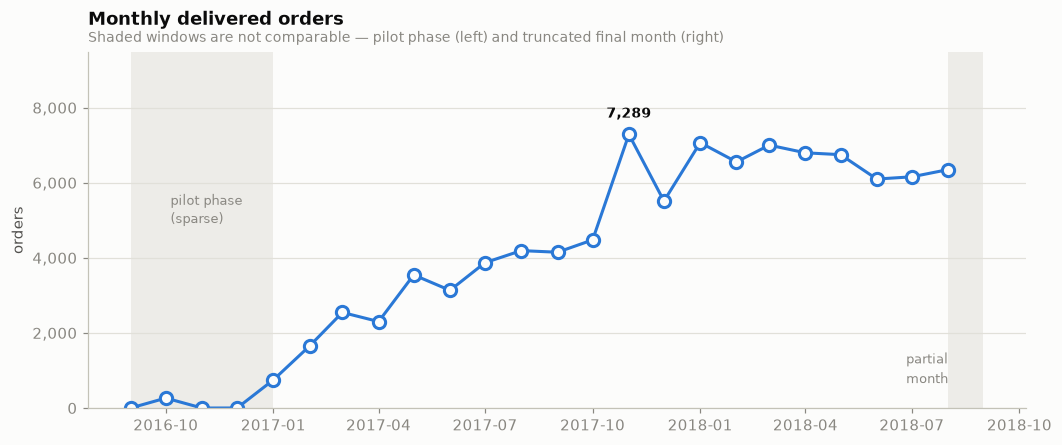

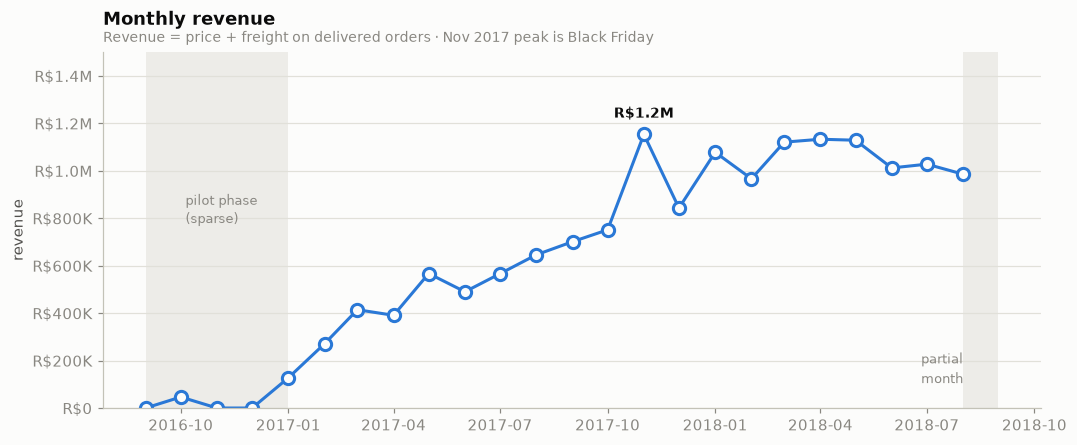

In [10]:
def trend(series, title, sub, ylabel, fmt=None, save=None, color=SERIES[0]):
    fig, ax = plt.subplots(figsize=(11, 4.2))
    ax.plot(series.index, series.values, color=color, marker="o",
            markerfacecolor=SURFACE, markeredgecolor=color, markeredgewidth=2)

    top = series.max() * 1.30
    ax.set_ylim(0, top)

    ax.axvspan(series.index.min(), pd.Timestamp(RELIABLE_FROM), color=GRID, alpha=.55, lw=0)
    ax.axvspan(pd.Timestamp(RELIABLE_TO) + pd.offsets.MonthEnd(0), series.index.max(),
               color=GRID, alpha=.55, lw=0)
    ax.text(pd.Timestamp("2016-10-05"), top*.52, "pilot phase\n(sparse)",
            fontsize=8.5, color=MUTED, ha="left", linespacing=1.4)
    ax.text(series.index.max(), top*.06, "partial\nmonth",
            fontsize=8.5, color=MUTED, ha="right", va="bottom", linespacing=1.4)

    pk = series.idxmax()
    ax.annotate(f"{fmt(series[pk]) if fmt else f'{series[pk]:,.0f}'}",
                (pk, series[pk]), textcoords="offset points", xytext=(0, 11),
                ha="center", fontsize=9, color=INK, fontweight="600")

    ax.set_ylabel(ylabel)
    if fmt: ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt))
    ax.grid(axis="x", visible=False)
    finish(ax, title, sub, save)

trend(monthly.orders, "Monthly delivered orders",
      "Shaded windows are not comparable — pilot phase (left) and truncated final month (right)",
      "orders", lambda x, _=None: f"{x:,.0f}", "monthly_orders")

trend(monthly.revenue, "Monthly revenue",
      "Revenue = price + freight on delivered orders · Nov 2017 peak is Black Friday",
      "revenue", brl, "monthly_revenue")

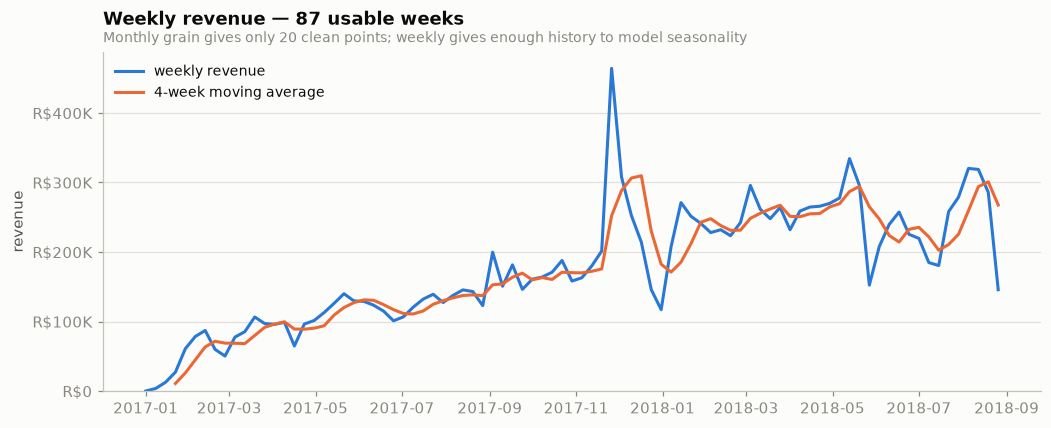

usable weekly observations: 87   vs monthly: 20


In [11]:
weekly = (delivered.set_index("order_purchase_timestamp")
                   .resample("W").item_revenue.sum())
weekly_clean = weekly[(weekly.index >= "2017-01-01") & (weekly.index <= "2018-08-31")]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(weekly_clean.index, weekly_clean.values, color=SERIES[0], lw=2)
ax.plot(weekly_clean.index, weekly_clean.rolling(4).mean(), color=SERIES[1], lw=2, ls="-")
ax.legend(["weekly revenue", "4-week moving average"], loc="upper left", fontsize=9)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(brl))
ax.set_ylabel("revenue"); ax.set_ylim(bottom=0); ax.grid(axis="x", visible=False)
finish(ax, f"Weekly revenue — {len(weekly_clean)} usable weeks",
       "Monthly grain gives only 20 clean points; weekly gives enough history to model seasonality",
       "weekly_revenue")

print(f"usable weekly observations: {len(weekly_clean)}   vs monthly: 20")

### Why the forecast must run at weekly grain

Twenty monthly observations cannot support a seasonal model — SARIMA needs at least two
full cycles before seasonal terms mean anything, and with 20 points it will fit noise.
The 87 weekly observations above carry the same signal with enough resolution to
validate on a real holdout. **Decision: `ml/sales_forecast.py` models weekly revenue.**

## 5 · Products & categories

In [12]:
tr = dict(zip(cat_tr.product_category_name, cat_tr.product_category_name_english))
tr.update({"pc_gamer": "pc_gamer",
           "portateis_cozinha_e_preparadores_de_alimentos": "kitchen_portables_food_preparers"})

prod = products.copy()
prod["category_en"] = (prod.product_category_name.map(tr)
                       .fillna(prod.product_category_name).fillna("unknown"))

dl = delivered.merge(prod[["product_id", "category_en"]], on="product_id", how="left")
cat = (dl.groupby("category_en")
         .agg(revenue=("item_revenue", "sum"),
              items=("order_id", "size"),
              orders=("order_id", "nunique"),
              avg_price=("price", "mean"))
         .sort_values("revenue", ascending=False))
cat["revenue_share_%"] = (100 * cat.revenue / cat.revenue.sum()).round(2)

TOP10_SHARE = cat["revenue_share_%"].head(10).sum()
print(f"{len(cat)} categories · top 10 hold {TOP10_SHARE:.1f}% of revenue\n")
cat.head(15).style.format({"revenue": "R$ {:,.0f}", "items": "{:,}", "orders": "{:,}",
                           "avg_price": "R$ {:,.2f}", "revenue_share_%": "{:.2f}%"})

74 categories · top 10 hold 62.4% of revenue



,revenue,items,orders,avg_price,revenue_share_%
category_en,,,,,
health_beauty,"R$ 1,412,090","9,465","8,647",R$ 130.28,9.16%
watches_gifts,"R$ 1,264,333","5,859","5,495",R$ 199.04,8.20%
bed_bath_table,"R$ 1,225,209","10,953","9,272",R$ 93.44,7.95%
sports_leisure,"R$ 1,118,257","8,431","7,530",R$ 113.25,7.25%
computers_accessories,"R$ 1,032,724","7,644","6,530",R$ 116.26,6.70%
furniture_decor,"R$ 880,330","8,160","6,307",R$ 87.25,5.71%
housewares,"R$ 758,392","6,795","5,743",R$ 90.60,4.92%
cool_stuff,"R$ 691,681","3,718","3,559",R$ 164.12,4.49%
auto,"R$ 669,455","4,140","3,810",R$ 139.85,4.34%


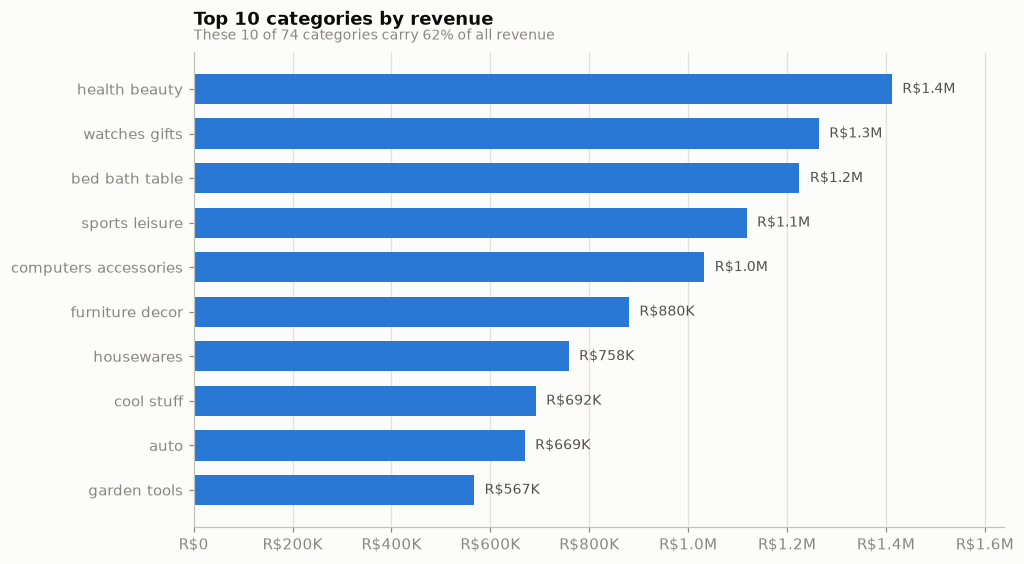

In [13]:
def hbar(s, title, sub, fmt, save, color=SERIES[0], highlight=None):
    s = s.sort_values()
    fig, ax = plt.subplots(figsize=(9.5, 0.42*len(s) + 1.4))
    colors = [CRITICAL if (highlight and i in highlight) else color for i in s.index]
    ax.barh(range(len(s)), s.values, color=colors, height=0.68)
    ax.set_yticks(range(len(s)), [str(i).replace("_", " ") for i in s.index], fontsize=9.5)
    pad = s.max() * 0.015
    for i, v in enumerate(s.values):
        ax.text(v + pad, i, fmt(v), va="center", fontsize=9, color=INK_2)
    ax.set_xlim(0, s.max() * 1.16)
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: fmt(x)))
    finish(ax, title, sub, save)

hbar(cat.revenue.head(10), "Top 10 categories by revenue",
     f"These 10 of {len(cat)} categories carry {TOP10_SHARE:.0f}% of all revenue",
     lambda x: brl(x), "top_categories")

In [14]:
sell = (delivered.groupby("seller_id")
        .agg(revenue=("item_revenue", "sum"), items=("order_id", "size"),
             orders=("order_id", "nunique"))
        .sort_values("revenue", ascending=False))

srev = reviews.merge(orders[["order_id"]], on="order_id")
sq = (order_items.merge(srev[["order_id", "review_score"]], on="order_id")
      .groupby("seller_id").review_score.mean())
sell["avg_review"] = sell.index.map(sq).round(2)

top_sellers = sell.head(10).copy()
top_sellers.index = [s[:8] + "…" for s in top_sellers.index]
print(f"{len(sell):,} sellers · top 10 hold {100*sell.revenue.head(10).sum()/sell.revenue.sum():.1f}% of revenue")
print(f"top 100 hold {100*sell.revenue.head(100).sum()/sell.revenue.sum():.1f}%\n")
top_sellers.style.format({"revenue": "R$ {:,.0f}", "items": "{:,}", "orders": "{:,}"})

2,970 sellers · top 10 hold 12.9% of revenue
top 100 hold 44.8%



,revenue,items,orders,avg_review
4869f7a5…,"R$ 247,007","1,148","1,124",4.120000
7c67e144…,"R$ 237,807","1,355",973,3.350000
4a3ca931…,"R$ 231,220","1,949","1,772",3.800000
53243585…,"R$ 230,797",400,348,4.080000
fa1c13f2…,"R$ 200,834",579,578,4.340000
da8622b1…,"R$ 184,707","1,548","1,311",4.070000
7e93a43e…,"R$ 171,974",322,319,4.210000
1025f0e2…,"R$ 171,925","1,420",910,3.850000
7a67c85e…,"R$ 160,279","1,155","1,145",4.230000
955fee92…,"R$ 156,606","1,472","1,261",4.050000


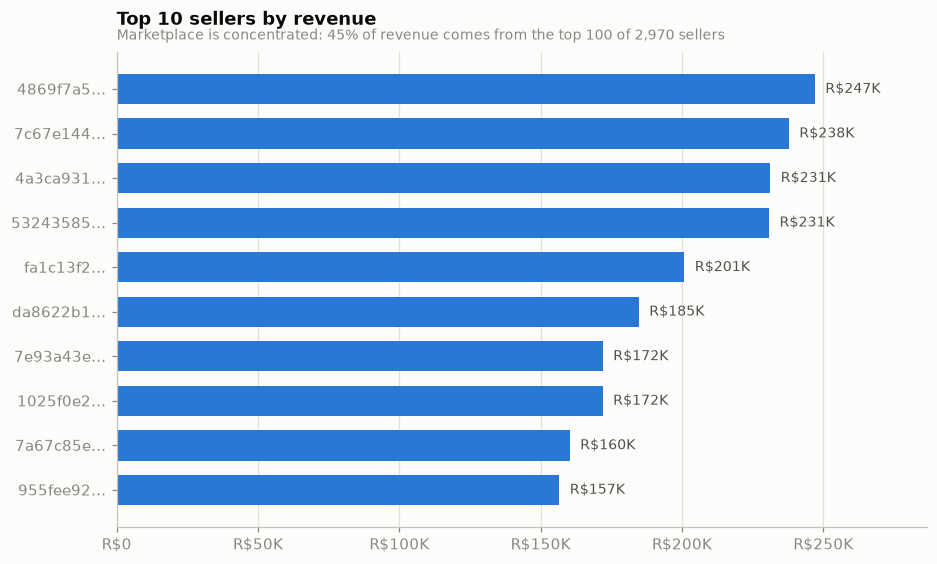

In [15]:
hbar(top_sellers.revenue, "Top 10 sellers by revenue",
     f"Marketplace is concentrated: {100*sell.revenue.head(100).sum()/sell.revenue.sum():.0f}% of revenue comes from the top 100 of {len(sell):,} sellers",
     brl, "top_sellers")

## 6 · Customer experience — reviews and delivery

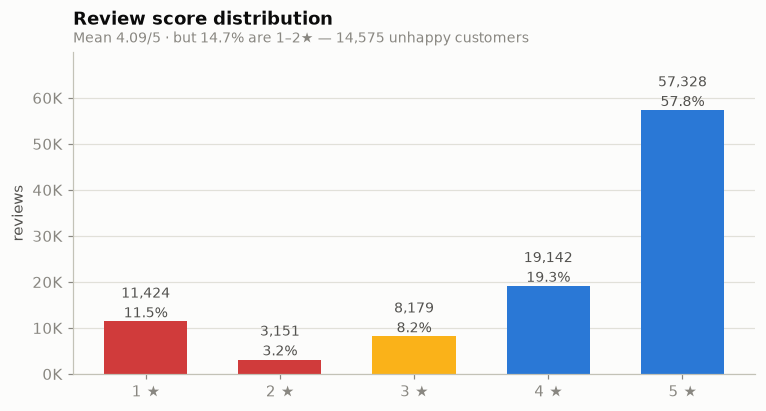

reviews with written text : 40,977 (41.3%)
negative reviews          : 14,575, of which 10,890 have text -> NLP training set


In [16]:
score_counts = reviews.review_score.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 3.8))
cols = [CRITICAL, CRITICAL, WARN, SERIES[0], SERIES[0]]
ax.bar(score_counts.index, score_counts.values, color=cols, width=0.62)
for x, v in score_counts.items():
    ax.text(x, v + 900, f"{v:,}\n{100*v/len(reviews):.1f}%", ha="center",
            fontsize=9, color=INK_2, linespacing=1.4)
ax.set_xticks([1, 2, 3, 4, 5], ["1 ★", "2 ★", "3 ★", "4 ★", "5 ★"])
ax.set_ylim(0, score_counts.max() * 1.22)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
ax.grid(axis="x", visible=False); ax.set_ylabel("reviews")
finish(ax, "Review score distribution",
       f"Mean {reviews.review_score.mean():.2f}/5 · but {100*(reviews.review_score<=2).mean():.1f}% are 1–2★ — {(reviews.review_score<=2).sum():,} unhappy customers",
       "review_scores")

print(f"reviews with written text : {reviews.review_comment_message.notna().sum():,} ({100*reviews.review_comment_message.notna().mean():.1f}%)")
neg = reviews[reviews.review_score <= 2]
print(f"negative reviews          : {len(neg):,}, of which {neg.review_comment_message.notna().sum():,} have text -> NLP training set")

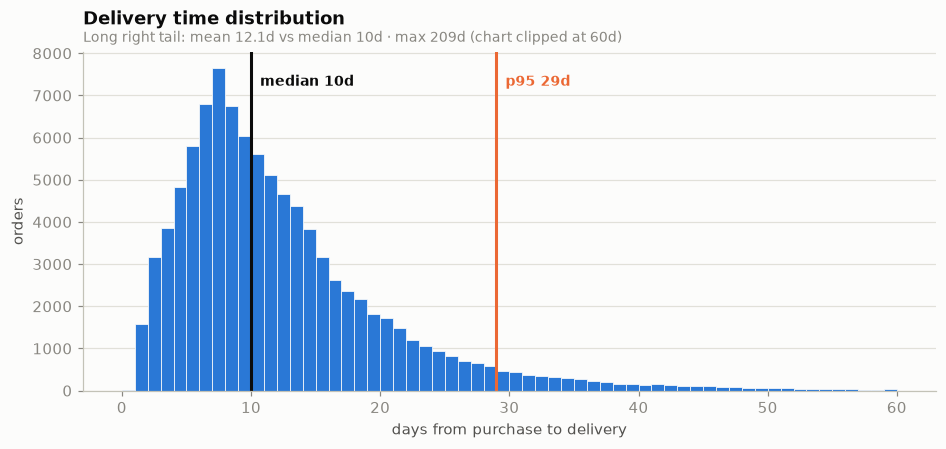

count    96470.0
mean        12.1
std          9.6
min          0.0
25%          6.0
50%         10.0
75%         15.0
90%         23.0
95%         29.0
99%         46.0
max        209.0


In [17]:
dd = od.delivery_days.dropna()

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(dd[dd <= 60], bins=60, color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
for val, lab, col in [(dd.median(), f"median {dd.median():.0f}d", INK),
                      (dd.quantile(.95), f"p95 {dd.quantile(.95):.0f}d", SERIES[1])]:
    ax.axvline(val, color=col, lw=2, ls="-")
    ax.text(val + 0.7, ax.get_ylim()[1]*0.9, lab, fontsize=9, color=col, fontweight="600")
ax.set_xlabel("days from purchase to delivery"); ax.set_ylabel("orders")
ax.grid(axis="x", visible=False)
finish(ax, "Delivery time distribution",
       f"Long right tail: mean {dd.mean():.1f}d vs median {dd.median():.0f}d · max {dd.max():.0f}d (chart clipped at 60d)",
       "delivery_time")

print(dd.describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(1).to_string())

findfont: Failed to find font weight 600, now using 700.


findfont: Failed to find font weight 600, now using 700.


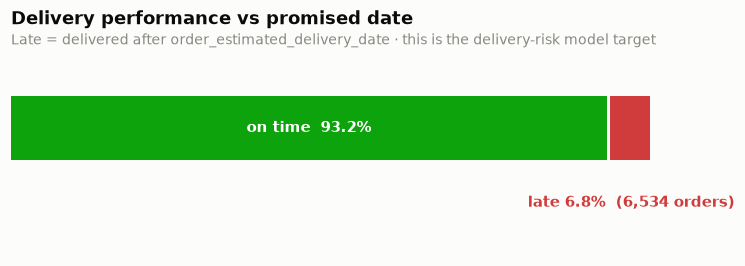

         mean  count
is_late             
0        4.29  89451
1        2.27   6381

Late deliveries average 2.27★ vs 4.29★ on time — a 2.02 star penalty.


In [18]:
late_rate = od.is_late.mean()
fig, ax = plt.subplots(figsize=(7.5, 2.4))
ax.barh([0], [1 - late_rate], color=GOOD, height=0.5)
ax.barh([0], [late_rate], left=[1 - late_rate + 0.004], color=CRITICAL, height=0.5)
ax.text((1-late_rate)/2, 0, f"on time  {100*(1-late_rate):.1f}%", ha="center", va="center",
        color="white", fontweight="600", fontsize=10)
ax.text(1 - late_rate/2 + 0.004, -0.62, f"late {100*late_rate:.1f}%  ({od.is_late.sum():,} orders)",
        ha="center", fontsize=9.5, color=CRITICAL, fontweight="600")
ax.set_xlim(0, 1); ax.set_ylim(-1, 0.6); ax.axis("off")
finish(ax, "Delivery performance vs promised date",
       "Late = delivered after order_estimated_delivery_date · this is the delivery-risk model target",
       "on_time_rate")

lr = od[["order_id", "is_late", "days_vs_estimate"]].merge(
        reviews[["order_id", "review_score"]].drop_duplicates("order_id"), on="order_id")
print(lr.groupby("is_late").review_score.agg(["mean", "count"]).round(2).to_string())
print(f"\nLate deliveries average {lr[lr.is_late==1].review_score.mean():.2f}★ vs "
      f"{lr[lr.is_late==0].review_score.mean():.2f}★ on time — a {lr[lr.is_late==0].review_score.mean()-lr[lr.is_late==1].review_score.mean():.2f} star penalty.")

**This is the single most important relationship in the dataset.** A late delivery costs
roughly **1.9 stars**. It links the operational layer (delivery risk) to the commercial
layer (reviews → repeat purchase), and it is the causal chain the AI advisor will
reason over: *predict the delay → prevent the bad review → protect the customer*.

## 7 · Payments

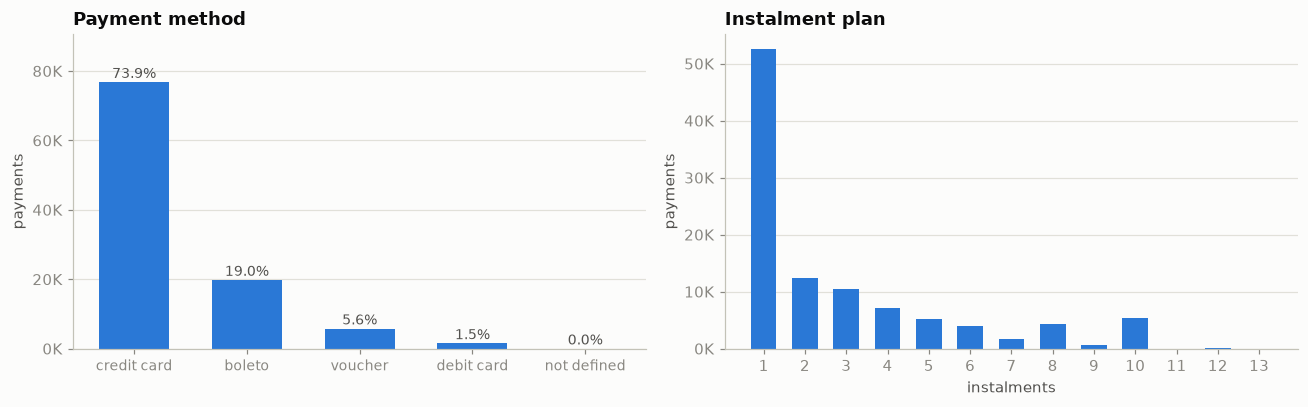

credit card share : 73.9%
orders paid in >1 instalment : 49.4%
mean instalments (credit card): 3.5


In [19]:
pay_type = payments.payment_type.value_counts()
inst = payments[payments.payment_installments > 0].payment_installments

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
a = axes[0]
a.bar(range(len(pay_type)), pay_type.values, color=SERIES[0], width=0.62)
a.set_xticks(range(len(pay_type)), [t.replace("_", " ") for t in pay_type.index], fontsize=9)
for i, v in enumerate(pay_type.values):
    a.text(i, v + 1200, f"{100*v/len(payments):.1f}%", ha="center", fontsize=9, color=INK_2)
a.set_ylim(0, pay_type.max()*1.18); a.grid(axis="x", visible=False); a.set_ylabel("payments")
a.set_title("Payment method", loc="left")
a.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))

b = axes[1]
ic = inst.value_counts().sort_index().head(13)
b.bar(ic.index, ic.values, color=SERIES[0], width=0.62)
b.set_xticks(range(1, 14)); b.grid(axis="x", visible=False)
b.set_xlabel("instalments"); b.set_ylabel("payments")
b.set_title("Instalment plan", loc="left")
b.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
plt.tight_layout(); plt.savefig(FIG / "payments.png"); plt.show()

print(f"credit card share : {100*(payments.payment_type=='credit_card').mean():.1f}%")
print(f"orders paid in >1 instalment : {100*(inst>1).mean():.1f}%")
print(f"mean instalments (credit card): {payments[payments.payment_type=='credit_card'].payment_installments.mean():.1f}")

## 8 · Geography

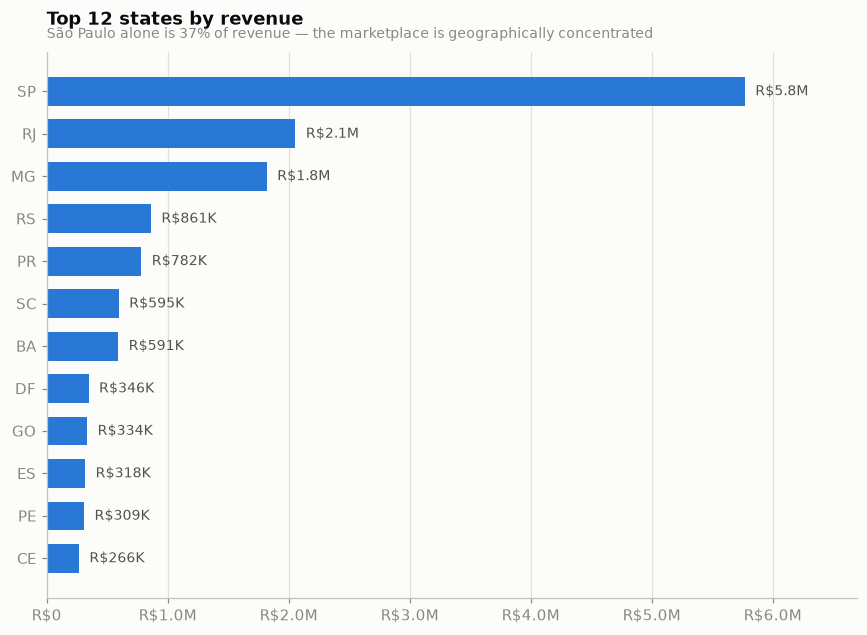

                orders     revenue  revenue_share_%  avg_days  late_rate
customer_state                                                          
SP               40501  5769703.15            37.42      8.30       0.04
RJ               12350  2055401.57            13.33     14.85       0.12
MG               11354  1818891.67            11.80     11.54       0.05
RS                5345   861472.79             5.59     14.82       0.06
PR                4923   781708.80             5.07     11.53       0.04
SC                3546   595127.78             3.86     14.48       0.08
BA                3256   591137.81             3.83     18.87       0.12
DF                2080   346123.35             2.24     12.51       0.06
GO                1957   334212.35             2.17     15.15       0.07
ES                1995   317657.93             2.06     15.33       0.11
PE                1593   308972.05             2.00     17.97        0.1
CE                1279   266436.77             1.73

In [20]:
state = (delivered.groupby("customer_state")
         .agg(orders=("order_id", "nunique"), revenue=("item_revenue", "sum"))
         .sort_values("revenue", ascending=False))
state["revenue_share_%"] = (100 * state.revenue / state.revenue.sum()).round(2)

state_delivery = od.merge(customers[["customer_id", "customer_state"]], on="customer_id") \
                   .groupby("customer_state").agg(avg_days=("delivery_days", "mean"),
                                                  late_rate=("is_late", "mean"))
state = state.join(state_delivery)

hbar(state.revenue.head(12), "Top 12 states by revenue",
     f"São Paulo alone is {state.loc['SP','revenue_share_%']:.0f}% of revenue — the marketplace is geographically concentrated",
     brl, "revenue_by_state")

print(state.head(12).round(2).to_string())

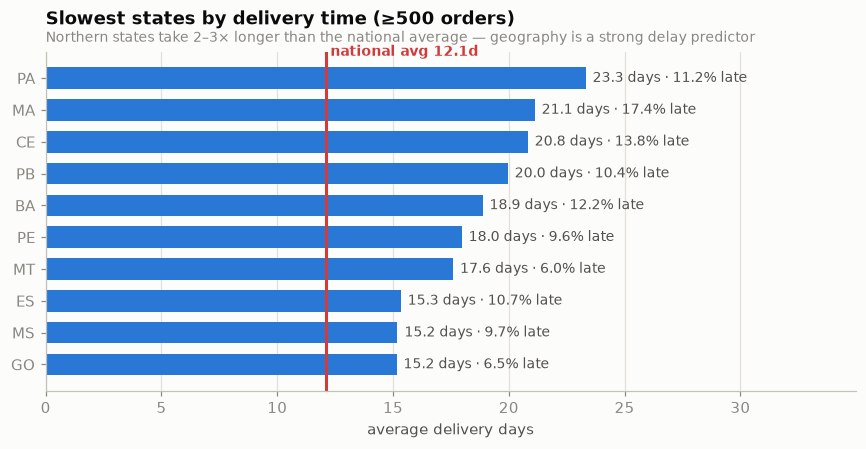

In [21]:
worst = (state[state.orders >= 500]
         .sort_values("avg_days", ascending=False).head(10)
         .iloc[::-1])
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.barh(range(len(worst)), worst.avg_days.values, color=SERIES[0], height=0.68)
ax.set_yticks(range(len(worst)), worst.index)
for i, (d, l) in enumerate(zip(worst.avg_days, worst.late_rate)):
    ax.text(d + 0.3, i, f"{d:.1f} days · {100*l:.1f}% late", va="center", fontsize=9, color=INK_2)
ax.axvline(od.delivery_days.mean(), color=CRITICAL, lw=2)
ax.text(od.delivery_days.mean() + 0.2, len(worst)-0.3, f"national avg {od.delivery_days.mean():.1f}d",
        fontsize=9, color=CRITICAL, fontweight="600")
ax.set_xlim(0, worst.avg_days.max()*1.5); ax.grid(axis="y", visible=False)
ax.set_xlabel("average delivery days")
finish(ax, "Slowest states by delivery time (≥500 orders)",
       "Northern states take 2–3× longer than the national average — geography is a strong delay predictor",
       "slowest_states")

## 9 · Repeat purchase behaviour

The finding that determines what the "churn" model can actually be.

unique customers (delivered)   : 93,358
customers with exactly 1 order : 90,557  (97.00%)
customers with 2+ orders       : 2,801  (3.00%)

          customers
order_id           
1             90557
2              2573
3               181
4                28
5                 9
6                 5
7                 3
9                 1


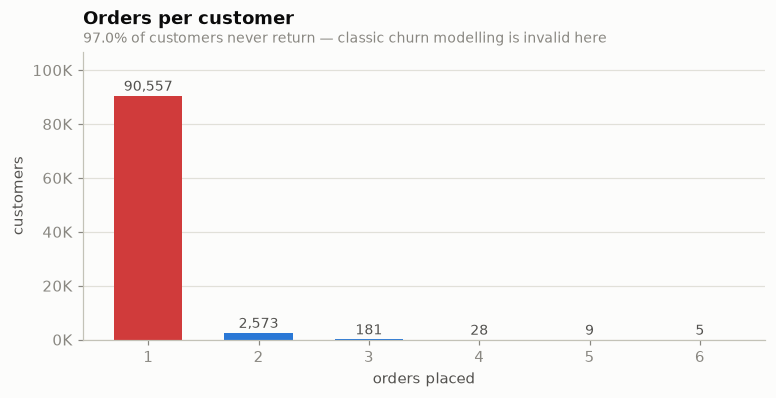

In [22]:
per_customer = delivered.groupby(PERSON_KEY).order_id.nunique()
dist = per_customer.value_counts().sort_index()

print(f"unique customers (delivered)   : {len(per_customer):,}")
print(f"customers with exactly 1 order : {dist.get(1, 0):,}  ({100*dist.get(1,0)/len(per_customer):.2f}%)")
print(f"customers with 2+ orders       : {(per_customer>1).sum():,}  ({100*(per_customer>1).mean():.2f}%)\n")
print(dist.head(8).to_frame("customers").to_string())

fig, ax = plt.subplots(figsize=(8, 3.4))
d = dist.head(6)
ax.bar(d.index, d.values, color=[CRITICAL] + [SERIES[0]]*(len(d)-1), width=0.62)
for x, v in d.items():
    ax.text(x, v + 1800, f"{v:,}", ha="center", fontsize=9, color=INK_2)
ax.set_yscale("linear"); ax.set_xlabel("orders placed"); ax.set_ylabel("customers")
ax.set_ylim(0, d.max()*1.18); ax.grid(axis="x", visible=False)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
finish(ax, "Orders per customer",
       f"{100*dist.get(1,0)/len(per_customer):.1f}% of customers never return — classic churn modelling is invalid here",
       "repeat_purchase")

### Consequence for Module 6 (machine learning)

With a **3.0% repeat rate**, a customer-churn classifier that predicts "will churn" for
everyone scores ~97% accuracy and has zero business value. The plan is therefore
re-scoped:

| Model | Target | Base rate | Verdict |
|---|---|---|---|
| ~~Customer churn (classic)~~ | will not return | 97% | **invalid — drop** |
| Seller churn | seller stops selling in next 90d | healthy | **headline model** |
| Repeat-purchase propensity | 2nd order within 180d | 3.0% | companion, scored on PR-AUC + lift |
| Delivery delay | late vs. estimate | 6.8% | strong |
| Weekly sales forecast | revenue | — | weekly grain |

Sellers are the right churn unit here: 3,095 of them, averaging ~36 orders each, and
retaining a seller is a genuine lever Olist can pull.

In [23]:
sa = (order_items.merge(orders[["order_id", "order_purchase_timestamp", "order_status"]], on="order_id")
      .query("order_status == @REVENUE_STATUS")
      .groupby("seller_id")
      .agg(orders=("order_id", "nunique"),
           first_sale=("order_purchase_timestamp", "min"),
           last_sale=("order_purchase_timestamp", "max")))
sa["active_days"] = (sa.last_sale - sa.first_sale).dt.days
cutoff = orders.order_purchase_timestamp.max()
sa["days_since_last_sale"] = (cutoff - sa.last_sale).dt.days
sa["dormant_90d"] = sa.days_since_last_sale > 90

print(f"sellers                       : {len(sa):,}")
print(f"median orders per seller      : {sa.orders.median():.0f}   (mean {sa.orders.mean():.1f})")
print(f"sellers with 10+ orders       : {(sa.orders>=10).sum():,}")
print(f"median active lifespan        : {sa.active_days.median():.0f} days")
print(f"DORMANT (no sale in 90d)      : {sa.dormant_90d.sum():,}  ({100*sa.dormant_90d.mean():.1f}%)  <- learnable churn target")

sellers                       : 2,970
median orders per seller      : 7   (mean 32.9)
sellers with 10+ orders       : 1,238
median active lifespan        : 116 days
DORMANT (no sale in 90d)      : 1,487  (50.1%)  <- learnable churn target


## 10 · Outliers — investigate, do not delete

Every "outlier" in this dataset was checked against the business reality before any
decision was taken. In a marketplace, extremes are usually **real and commercially
important**, and deleting them quietly removes exactly the high-value orders and
service failures the platform most needs to predict.

In [24]:
def outlier_report(s, name, unit=""):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    hi = q3 + 1.5*iqr
    n = int((s > hi).sum())
    return {"metric": name, "median": round(s.median(), 2), "p99": round(s.quantile(.99), 2),
            "max": round(s.max(), 2), "IQR upper fence": round(hi, 2),
            "above fence": f"{n:,} ({100*n/len(s):.2f}%)"}

rep = pd.DataFrame([
    outlier_report(order_items.price, "item price (R$)"),
    outlier_report(order_items.freight_value, "freight (R$)"),
    outlier_report(order_revenue, "order value (R$)"),
    outlier_report(od.delivery_days.dropna(), "delivery days"),
    outlier_report(products.product_weight_g.dropna(), "product weight (g)"),
]).set_index("metric")
print(rep.to_string())

                    median       p99       max  IQR upper fence      above fence
metric                                                                          
item price (R$)      74.99    890.00   6735.00           277.40    8,427 (7.48%)
freight (R$)         16.26     84.52    409.68            33.25  11,613 (10.31%)
order value (R$)    105.28   1052.39  13664.08           347.88    7,579 (7.86%)
delivery days        10.00     46.00    209.00            28.50    5,022 (5.21%)
product weight (g)  700.00  22538.00  40425.00          4300.00   4,551 (13.81%)


In [25]:
print("Are the extremes real? Inspect the actual records:\n")
top_items = (order_items.nlargest(5, "price")
             .merge(prod[["product_id", "category_en"]], on="product_id")
             [["order_id", "category_en", "price", "freight_value"]])
print("Highest-priced items:")
print(top_items.to_string(index=False))

print("\nSlowest deliveries:")
slow = od.nlargest(5, "delivery_days")[["order_id", "order_purchase_timestamp",
                                        "order_delivered_customer_date", "delivery_days",
                                        "days_vs_estimate"]]
print(slow.to_string(index=False))

print("""
Verdict
  price R$6,735          -> a real high-value category purchase, not a typo. KEEP.
  delivery 209 days      -> a genuine logistics failure. KEEP - this is the event
                            the delivery-risk model exists to predict.
  freight > price        -> real for heavy, low-value goods. KEEP, flag as a feature.
ETL will WINSORIZE at p99 for model training only, never for reported revenue.
""")

Are the extremes real? Inspect the actual records:

Highest-priced items:
                        order_id      category_en  price  freight_value
0812eb902a67711a1cb742b3cdaa65ae       housewares 6735.0         194.31
fefacc66af859508bf1a7934eab1e97f        computers 6729.0         193.21
f5136e38d1a14a4dbd87dff67da82701              art 6499.0         227.66
a96610ab360d42a2e5335a3998b4718a small_appliances 4799.0         151.34
199af31afc78c699f0dbf71fb178d4d4 small_appliances 4690.0          74.34

Slowest deliveries:
                        order_id order_purchase_timestamp order_delivered_customer_date  delivery_days  days_vs_estimate
ca07593549f1816d26a572e06dc1eab6      2017-02-21 23:31:27           2017-09-19 14:36:39          209.0             181.0
1b3190b2dfa9d789e1f14c05b647a14a      2018-02-23 14:57:35           2018-09-19 23:24:07          208.0             188.0
440d0d17af552815d15a9e41abe49359      2017-03-07 23:59:51           2017-09-19 15:12:50          195.0        

## 11 · Findings → ETL requirements

Everything Module 3 (`etl/transform.py`, `etl/validate.py`) must implement.

### Cleaning rules

| # | Rule |
|---|---|
| 1 | Parse all five order date columns to datetime; never impute a missing delivery date |
| 2 | Collapse `geolocation` to one row per zip prefix (median lat/lng, modal city/state) |
| 3 | Deduplicate `reviews` on `order_id`, keeping the latest `review_answer_timestamp` |
| 4 | Aggregate `payments` to one row per order: `SUM(payment_value)`, `MAX(installments)`, dominant `payment_type` |
| 5 | Translate categories to English; patch `pc_gamer` + `portateis_cozinha…`; nulls → `unknown` |
| 6 | Fill the 2 missing product weight/dimension rows with the category median |
| 7 | Standardise city names (lowercase, strip accents) — 4,119 customer cities are dirty |
| 8 | Keep all order statuses; the `delivered` filter is applied in the KPI layer, not in ETL |

### Engineered features

| Feature | Definition |
|---|---|
| `delivery_days` | delivered − purchase |
| `approval_hours` | approved − purchase |
| `shipping_days` | carrier pickup − approved |
| `days_vs_estimate` | delivered − estimated (negative = early) |
| `is_late` | `days_vs_estimate > 0` |
| `estimated_delivery_days` | estimated − purchase (**known at purchase — safe for the delay model**) |
| `item_revenue` | `price + freight_value` |
| `freight_ratio` | `freight_value / price` |
| `product_volume_cm3` | length × height × width |
| `seller_customer_distance_km` | haversine between seller and customer zip centroids |
| `order_item_count` | items per order |
| `is_weekend_purchase`, `purchase_hour`, `purchase_month` | temporal features |
| RFM per `customer_unique_id` | recency, frequency, monetary |

### Validation gates (`etl/validate.py` must fail loudly on any of these)

1. Zero orphan foreign keys on all four fact→dimension joins
2. `customer_unique_id` count == 96,096
3. `geolocation` row count == unique zip prefix count after collapsing
4. No duplicate `(order_id, order_item_id)` pairs
5. `SUM(item_revenue)` over delivered orders reconciles to **R$ 15,419,774** ±R$1
6. No negative prices, freight values or delivery days
7. Every product category resolves to a non-null English name
8. Date range within 2016-09-04 → 2018-10-17

### Baseline numbers the warehouse must reproduce

| KPI | Value |
|---|---|
| Total orders | 99,441 |
| Delivered orders | 96,478 |
| Unique customers | 96,096 |
| Sellers | 3,095 |
| Revenue (delivered) | R$ 15,419,774 |
| Average order value | ~R$ 159.85 |
| Average review score | 4.09 / 5 |
| Average delivery time | 12.1 days |
| On-time rate | 93.2% |
| Repeat-purchase rate | 3.00% |